In [1]:
import pandas as pd
import numpy as np

df=pd.read_csv("used_device_data.csv")
df.head()

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [2]:
#ishe pata chalega ki kaha data missing hai or kawn se column hai 
print(df.shape)
df.info()

(3454, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   device_brand           3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   rear_camera_mp         3275 non-null   float64
 6   front_camera_mp        3452 non-null   float64
 7   internal_memory        3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float6

In [3]:
#missing values gine hai 
df.isnull().sum()

device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64

In [4]:
#missing values ko bharna hai 
cols = ["rear_camera_mp","front_camera_mp","internal_memory","ram","battery","weight"]
for c in cols:
    df[c]=df[c].fillna(df[c].median())

In [5]:
#check kar rahe hai ki sara values zeroes hua hai ya nahi 
df.isnull().sum()

device_brand             0
os                       0
screen_size              0
4g                       0
5g                       0
rear_camera_mp           0
front_camera_mp          0
internal_memory          0
ram                      0
battery                  0
weight                   0
release_year             0
days_used                0
normalized_used_price    0
normalized_new_price     0
dtype: int64

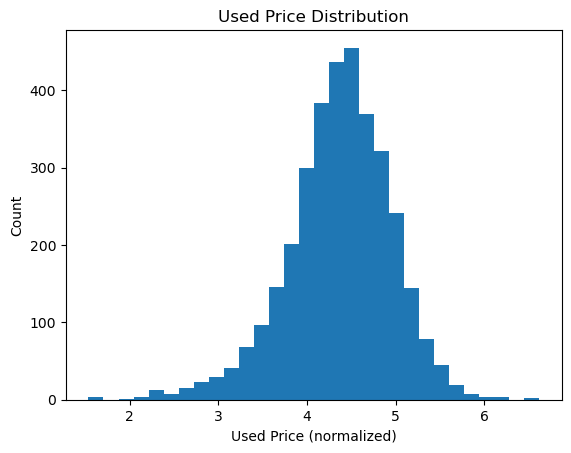

,screen_size,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
count,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000,3454.000000
mean,13.713115,9.384534,6.553329,54.546957,4.036080,3133.170961,182.705761,2015.965258,674.869716,4.364712,5.233107
std,3.805280,4.700148,6.968453,84.926611,1.364314,1298.565062,88.329494,2.298455,248.580166,0.588914,0.683637
min,5.080000,0.080000,0.000000,0.010000,0.020000,500.000000,69.000000,2013.000000,91.000000,1.536867,2.901422
25%,12.700000,5.000000,2.000000,16.000000,4.000000,2100.000000,142.000000,2014.000000,533.500000,4.033931,4.790342
50%,12.830000,8.000000,5.000000,32.000000,4.000000,3000.000000,160.000000,2015.500000,690.500000,4.405133,5.245892
75%,15.340000,13.000000,8.000000,64.000000,4.000000,4000.000000,185.000000,2018.000000,868.750000,4.755700,5.673718
max,30.710000,48.000000,32.000000,1024.000000,12.000000,9720.000000,855.000000,2020.000000,1094.000000,6.619433,7.847841


In [6]:
#ishe check kar rahe hai ki sabse jada kis price me data use hua hai 
import matplotlib.pyplot as plt

plt.hist(df["normalized_used_price"], bins=30)
plt.xlabel("Used Price (normalized)")
plt.ylabel("Count")
plt.title("Used Price Distribution")
plt.show()
df.describe()

In [7]:
#jis ka -values aaya hai use incres hone par price decres hota hai 
df.corr(numeric_only=True)["normalized_used_price"].sort_values(ascending=False)

normalized_used_price    1.000000
normalized_new_price     0.834496
screen_size              0.614785
battery                  0.612041
front_camera_mp          0.607548
rear_camera_mp           0.552477
ram                      0.518783
release_year             0.509790
weight                   0.382456
internal_memory          0.190954
days_used               -0.358264
Name: normalized_used_price, dtype: float64

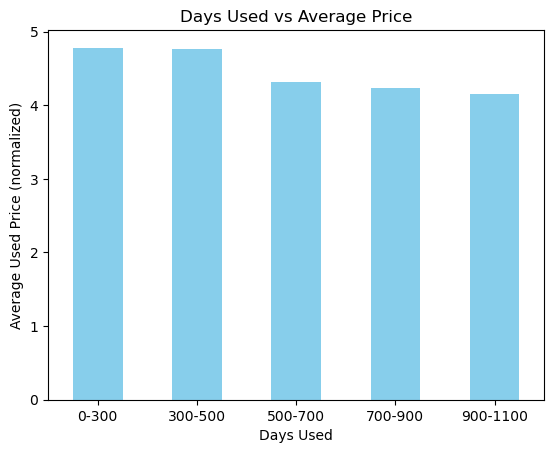

In [8]:
# ye day used ka graph banaiga 
groups = pd.cut(df["days_used"], bins=[0, 300, 500, 700, 900, 1100],
                labels=["0-300", "300-500", "500-700", "700-900", "900-1100"])

avg_price = df.groupby(groups, observed=True)["normalized_used_price"].mean()

avg_price.plot(kind="bar", color="skyblue")
plt.xlabel("Days Used")
plt.ylabel("Average Used Price (normalized)")
plt.title("Days Used vs Average Price")
plt.xticks(rotation=0)
plt.show()

In [9]:
#model shirf number shamgta hai text nahi samjhata hai ishi lia text wala bhi number me conver karege 
df_model = pd.get_dummies(df, columns=["device_brand", "os", "4g", "5g"], drop_first=True)
df_model.shape

(3454, 49)

In [10]:
#input(x) or target value(y) aalg kare or phir test kar rahe hai (80%data use kar ke 20% data ko pridict kar rahe hai )
from sklearn.model_selection import train_test_split

X = df_model.drop("normalized_used_price", axis=1)
y = df_model["normalized_used_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(2763, 48) (691, 48)


In [11]:
#modal train kar rahe hai 1 linear regression 
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
# test data par check kar rahe hai 
from sklearn.metrics import r2_score, mean_absolute_error

pred = lr.predict(X_test)

print("R2 Score:", r2_score(y_test, pred))
print("MAE:", mean_absolute_error(y_test, pred))

R2 Score: 0.8357287938257505
MAE: 0.18437999841091654


In [13]:
#random forest se test karte hai 
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [14]:
pred_rf = rf.predict(X_test)

print("RF R2 Score:", r2_score(y_test, pred_rf))
print("RF MAE:", mean_absolute_error(y_test, pred_rf))

RF R2 Score: 0.8519540681831765
RF MAE: 0.17572774493285087


In [15]:
import joblib

joblib.dump(rf, "used_phone_model.pkl")
joblib.dump(list(X.columns), "model_columns.pkl")

['model_columns.pkl']

In [16]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'archive (2).zip', 'brands.pkl', 'defaults.pkl', 'euro_to_inr.pkl', 'model_columns.pkl', 'phones.pkl', 'phones_old.pkl', 'Project1.ipynb', 'run_dashboard.bat', 'smartphones.csv', 'used_device_data.csv', 'used_phone_model.pkl']


In [17]:
#defult value tayar karte hai 
import numpy as np

EURO_TO_INR = 100
model_cols = list(X.columns)
defaults = X.astype(float).median()

joblib.dump(defaults, "defaults.pkl")
print(sorted(df["device_brand"].unique()))

['Acer', 'Alcatel', 'Apple', 'Asus', 'BlackBerry', 'Celkon', 'Coolpad', 'Gionee', 'Google', 'HTC', 'Honor', 'Huawei', 'Infinix', 'Karbonn', 'LG', 'Lava', 'Lenovo', 'Meizu', 'Micromax', 'Microsoft', 'Motorola', 'Nokia', 'OnePlus', 'Oppo', 'Others', 'Panasonic', 'Realme', 'Samsung', 'Sony', 'Spice', 'Vivo', 'XOLO', 'Xiaomi', 'ZTE']


In [18]:
#ishe price nikalte hai 
def predict_price(brand, days_used, ram, new_price_inr):
    row = defaults.copy()
    row["days_used"] = days_used
    row["ram"] = ram
    row["normalized_new_price"] = np.log(new_price_inr / EURO_TO_INR)

    col = "device_brand_" + brand
    if col in row.index:
        row[col] = 1

    x = pd.DataFrame([row])[model_cols]
    pred = rf.predict(x)[0]
    return np.exp(pred) * EURO_TO_INR

print(predict_price("Samsung", 500, 4, 20000))

7341.7592660905


In [19]:
def final_price(brand, days_used, ram, new_price_inr,
                camera_ok=True, speaker_ok=True, touch_ok=True):
    price = predict_price(brand, days_used, ram, new_price_inr)

    if not camera_ok:
        price *= 0.85   # 15% kam
    if not speaker_ok:
        price *= 0.92   # 8% kam
    if not touch_ok:
        price *= 0.70   # 30% kam

    return round(price)

print(final_price("Samsung", 500, 4, 20000))
print(final_price("Samsung", 500, 4, 20000, camera_ok=False, touch_ok=False))

7342
4368


In [20]:
import os
joblib.dump(sorted(df["device_brand"].unique()), "brands.pkl")
joblib.dump(EURO_TO_INR, "euro_to_inr.pkl")
print(os.listdir())

['.ipynb_checkpoints', 'app.py', 'archive (2).zip', 'brands.pkl', 'defaults.pkl', 'euro_to_inr.pkl', 'model_columns.pkl', 'phones.pkl', 'phones_old.pkl', 'Project1.ipynb', 'run_dashboard.bat', 'smartphones.csv', 'used_device_data.csv', 'used_phone_model.pkl']


In [21]:
# %%writefile app.py
# import streamlit as st
# import pandas as pd
# import numpy as np
# import joblib

# rf = joblib.load("used_phone_model.pkl")
# model_cols = joblib.load("model_columns.pkl")
# defaults = joblib.load("defaults.pkl")
# brands = joblib.load("brands.pkl")
# EURO_TO_INR = joblib.load("euro_to_inr.pkl")


# def predict_price(brand, days_used, ram, new_price_inr):
#     row = defaults.copy()
#     row["days_used"] = days_used
#     row["ram"] = ram
#     row["normalized_new_price"] = np.log(new_price_inr / EURO_TO_INR)
#     col = "device_brand_" + brand
#     if col in row.index:
#         row[col] = 1
#     x = pd.DataFrame([row])[model_cols]
#     return np.exp(rf.predict(x)[0]) * EURO_TO_INR


# def final_price(brand, days_used, ram, new_price_inr,
#                 camera_ok=True, speaker_ok=True, touch_ok=True):
#     price = predict_price(brand, days_used, ram, new_price_inr)
#     if not camera_ok:
#         price *= 0.85
#     if not speaker_ok:
#         price *= 0.92
#     if not touch_ok:
#         price *= 0.70
#     return round(price)


# st.title("📱 Used Mobile Price Prediction")

# brand = st.selectbox("Brand", brands, index=brands.index("Samsung"))
# days_used = st.slider("Kitne din use hua (days)", 0, 1100, 500)
# ram = st.selectbox("RAM (GB)", [1, 2, 3, 4, 6, 8, 12], index=3)
# new_price = st.number_input("Kharidte time ka price (₹)", min_value=1000,
#                             value=20000, step=500)

# st.subheader("Phone ki condition")
# camera_ok = st.checkbox("Camera working", value=True)
# speaker_ok = st.checkbox("Speaker working", value=True)
# touch_ok = st.checkbox("Touch working", value=True)

# price = final_price(brand, days_used, ram, new_price,
#                     camera_ok, speaker_ok, touch_ok)
# st.success(f"Estimated used price: ₹{price:,}")

In [22]:
# !streamlit run app.py

In [23]:
# %%writefile -a app.py


# st.markdown("""
# <style>
# /* poora background: ad jaisa gradient */
# .stApp {
#     background: linear-gradient(135deg, #1e1b4b 0%, #5b21b6 50%, #ec4899 100%);
# }

# /* title */
# h1 {
#     color: #ffffff !important;
#     text-align: center;
#     font-weight: 800;
#     text-shadow: 0 3px 12px rgba(0,0,0,0.35);
# }

# /* sub heading aur labels */
# h2, h3,
# [data-testid="stWidgetLabel"] p,
# [data-testid="stCheckbox"] p {
#     color: #ffffff !important;
#     font-weight: 600;
# }

# /* price wala bada card */
# [data-testid="stAlert"] {
#     background: linear-gradient(90deg, #facc15, #fb923c);
#     border: none;
#     border-radius: 18px;
#     box-shadow: 0 8px 24px rgba(0,0,0,0.35);
# }
# [data-testid="stAlert"] p {
#     color: #1e1b4b !important;
#     font-size: 30px;
#     font-weight: 800;
#     text-align: center;
# }
# </style>
# """, unsafe_allow_html=True)

In [24]:
print(model_cols)
print(df.head(3).T)

['screen_size', 'rear_camera_mp', 'front_camera_mp', 'internal_memory', 'ram', 'battery', 'weight', 'release_year', 'days_used', 'normalized_new_price', 'device_brand_Alcatel', 'device_brand_Apple', 'device_brand_Asus', 'device_brand_BlackBerry', 'device_brand_Celkon', 'device_brand_Coolpad', 'device_brand_Gionee', 'device_brand_Google', 'device_brand_HTC', 'device_brand_Honor', 'device_brand_Huawei', 'device_brand_Infinix', 'device_brand_Karbonn', 'device_brand_LG', 'device_brand_Lava', 'device_brand_Lenovo', 'device_brand_Meizu', 'device_brand_Micromax', 'device_brand_Microsoft', 'device_brand_Motorola', 'device_brand_Nokia', 'device_brand_OnePlus', 'device_brand_Oppo', 'device_brand_Others', 'device_brand_Panasonic', 'device_brand_Realme', 'device_brand_Samsung', 'device_brand_Sony', 'device_brand_Spice', 'device_brand_Vivo', 'device_brand_XOLO', 'device_brand_Xiaomi', 'device_brand_ZTE', 'os_Others', 'os_Windows', 'os_iOS', '4g_yes', '5g_yes']
                              0       

In [25]:
# (brand, screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g, os)
raw = {
 "Samsung Galaxy M31":     ("Samsung", 6.4, 64, 32, 128, 6, 6000, 191, 2020, "no", "Android"),
 "Samsung Galaxy S10":     ("Samsung", 6.1, 12, 10, 128, 8, 3400, 157, 2019, "no", "Android"),
 "Redmi Note 10":          ("Xiaomi", 6.43, 48, 13, 128, 4, 5000, 179, 2021, "no", "Android"),
 "Redmi Note 9 Pro":       ("Xiaomi", 6.67, 48, 16, 128, 6, 5020, 209, 2020, "no", "Android"),
 "Realme 8":               ("Realme", 6.4, 64, 16, 128, 6, 5000, 177, 2021, "no", "Android"),
 "Oppo A54":               ("Oppo", 6.51, 13, 16, 64, 4, 5000, 192, 2021, "no", "Android"),
 "Vivo Y20":               ("Vivo", 6.51, 13, 8, 64, 4, 5000, 192, 2020, "no", "Android"),
 "OnePlus 8T":             ("OnePlus", 6.55, 48, 16, 128, 8, 4500, 188, 2020, "yes", "Android"),
 "OnePlus Nord":           ("OnePlus", 6.44, 48, 32, 128, 8, 4115, 184, 2020, "yes", "Android"),
 "Motorola Moto G60":      ("Motorola", 6.8, 108, 32, 128, 6, 6000, 225, 2021, "no", "Android"),
 "Nokia 5.3":              ("Nokia", 6.55, 13, 8, 64, 4, 4000, 185, 2020, "no", "Android"),
 "Google Pixel 4a":        ("Google", 5.81, 12, 8, 128, 6, 3140, 143, 2020, "no", "Android"),
 "Apple iPhone XR":        ("Apple", 6.1, 12, 7, 64, 3, 2942, 194, 2018, "no", "iOS"),
 "Apple iPhone 11":        ("Apple", 6.1, 12, 12, 64, 4, 3110, 194, 2019, "no", "iOS"),
 "Apple iPhone 12":        ("Apple", 6.1, 12, 12, 64, 4, 2815, 164, 2020, "yes", "iOS"),
}

phones = {}
for name, (b, s, rc, fc, mem, ram, bat, w, yr, g5, os_) in raw.items():
    phones[name] = dict(brand=b, screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os=os_)

joblib.dump(phones, "phones.pkl")
print(len(phones), "phones saved")

15 phones saved


In [26]:
# (brand, screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g, os)
raw.update({
 "Moto G13":      ("Motorola", 6.5, 50, 8, 128, 4, 5000, 184, 2023, "no", "Android"),
 "Moto G23":      ("Motorola", 6.5, 50, 8, 128, 8, 5000, 184, 2023, "no", "Android"),
 "Moto G31":      ("Motorola", 6.4, 50, 13, 64, 4, 5000, 181, 2021, "no", "Android"),
 "Moto G32":      ("Motorola", 6.5, 50, 16, 128, 4, 5000, 185, 2022, "no", "Android"),
 "Moto G42":      ("Motorola", 6.4, 50, 16, 128, 4, 5000, 177, 2022, "no", "Android"),
 "Moto G53":      ("Motorola", 6.5, 50, 8, 128, 4, 5000, 183, 2023, "yes", "Android"),
 "Moto G62 5G":   ("Motorola", 6.5, 50, 16, 128, 6, 5000, 184, 2022, "yes", "Android"),
 "Moto G73":      ("Motorola", 6.5, 50, 16, 256, 8, 5000, 181, 2023, "yes", "Android"),
 "Moto G82 5G":   ("Motorola", 6.6, 50, 16, 128, 6, 5000, 173, 2022, "yes", "Android"),
 "Moto Edge 40":  ("Motorola", 6.55, 50, 32, 256, 8, 4400, 167, 2023, "yes", "Android"),
})

phones = {}
for name, (b, s, rc, fc, mem, ram, bat, w, yr, g5, os_) in raw.items():
    phones[name] = dict(brand=b, screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os=os_)

joblib.dump(phones, "phones.pkl")
print(len(phones), "phones saved")
print([n for n, p in phones.items() if p["brand"] == "Motorola"])

25 phones saved
['Motorola Moto G60', 'Moto G13', 'Moto G23', 'Moto G31', 'Moto G32', 'Moto G42', 'Moto G53', 'Moto G62 5G', 'Moto G73', 'Moto G82 5G', 'Moto Edge 40']


In [27]:
# (brand, screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g, os)
raw.update({
 "Galaxy A12":     ("Samsung", 6.5, 48, 8, 64, 4, 5000, 205, 2020, "no", "Android"),
 "Galaxy A32":     ("Samsung", 6.4, 64, 20, 128, 6, 5000, 205, 2021, "no", "Android"),
 "Galaxy A52":     ("Samsung", 6.5, 64, 32, 128, 6, 4500, 189, 2021, "no", "Android"),
 "Galaxy A53 5G":  ("Samsung", 6.5, 64, 32, 128, 6, 5000, 189, 2022, "yes", "Android"),
 "Galaxy M12":     ("Samsung", 6.5, 48, 8, 64, 4, 6000, 221, 2021, "no", "Android"),
 "Galaxy M32":     ("Samsung", 6.4, 64, 20, 128, 6, 5000, 196, 2021, "no", "Android"),
 "Galaxy M33 5G":  ("Samsung", 6.6, 50, 8, 128, 6, 6000, 215, 2022, "yes", "Android"),
 "Galaxy F13":     ("Samsung", 6.6, 50, 8, 64, 4, 6000, 207, 2022, "no", "Android"),
 "Galaxy S20 FE":  ("Samsung", 6.5, 12, 32, 128, 6, 4500, 190, 2020, "no", "Android"),
 "Galaxy S21":     ("Samsung", 6.2, 12, 10, 128, 8, 4000, 169, 2021, "yes", "Android"),
})

phones = {}
for name, (b, s, rc, fc, mem, ram, bat, w, yr, g5, os_) in raw.items():
    phones[name] = dict(brand=b, screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os=os_)

joblib.dump(phones, "phones.pkl")
print(len(phones), "phones saved")
print([n for n, p in phones.items() if p["brand"] == "Samsung"])

35 phones saved
['Samsung Galaxy M31', 'Samsung Galaxy S10', 'Galaxy A12', 'Galaxy A32', 'Galaxy A52', 'Galaxy A53 5G', 'Galaxy M12', 'Galaxy M32', 'Galaxy M33 5G', 'Galaxy F13', 'Galaxy S20 FE', 'Galaxy S21']


In [28]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

rf = joblib.load("used_phone_model.pkl")
model_cols = joblib.load("model_columns.pkl")
defaults = joblib.load("defaults.pkl")
EURO_TO_INR = joblib.load("euro_to_inr.pkl")
phones = joblib.load("phones.pkl")


def predict_price(phone, days_used, new_price_inr):
    row = defaults.copy()
    row["screen_size"] = phone["screen_size"]
    row["rear_camera_mp"] = phone["rear_camera_mp"]
    row["front_camera_mp"] = phone["front_camera_mp"]
    row["internal_memory"] = phone["internal_memory"]
    row["ram"] = phone["ram"]
    row["battery"] = phone["battery"]
    row["weight"] = phone["weight"]
    row["release_year"] = phone["release_year"]
    row["days_used"] = days_used
    row["normalized_new_price"] = np.log(new_price_inr / EURO_TO_INR)
    row["4g_yes"] = 1
    row["5g_yes"] = 1 if phone["g5"] == "yes" else 0

    col = "device_brand_" + phone.get("pred_brand", phone["brand"])
    if col not in row.index:
        col = "device_brand_Others"
    row[col] = 1
    if phone["os"] == "iOS" and "os_iOS" in row.index:
        row["os_iOS"] = 1

    x = pd.DataFrame([row])[model_cols]
    return np.exp(rf.predict(x)[0]) * EURO_TO_INR


def final_price(phone, days_used, new_price_inr,
                camera_ok=True, speaker_ok=True, touch_ok=True):
    price = predict_price(phone, days_used, new_price_inr)
    cap = new_price_inr * max(0.15, 0.85 - 0.55 * days_used / 1095)
    price = min(price, cap)
    if not camera_ok:
        price *= 0.85
    if not speaker_ok:
        price *= 0.92
    if not touch_ok:
        price *= 0.70
    return round(price)


st.markdown("""
<style>
.stApp {
    background:
        radial-gradient(circle at 15% 20%, rgba(236,72,153,0.45), transparent 40%),
        radial-gradient(circle at 85% 75%, rgba(56,189,248,0.40), transparent 40%),
        linear-gradient(135deg, #0f0c29, #302b63, #24243e);
}

/* background me do phone */
.stApp::before, .stApp::after {
    content: "";
    position: fixed;
    width: 170px; height: 340px;
    border: 6px solid rgba(255,255,255,0.35);
    border-radius: 34px;
    background: linear-gradient(160deg, rgba(255,255,255,0.18), rgba(255,255,255,0.03));
    box-shadow: 0 20px 60px rgba(0,0,0,0.4), inset 0 0 25px rgba(255,255,255,0.12);
    pointer-events: none;
    z-index: 0;
}
.stApp::before { left: 4%; top: 18%; transform: rotate(-14deg); }
.stApp::after  { right: 4%; bottom: 10%; width: 200px; height: 400px; transform: rotate(12deg); }
@media (max-width: 900px) { .stApp::before, .stApp::after { display: none; } }

[data-testid="stHeader"] { background: transparent; }

/* glass card */
.block-container {
    position: relative; z-index: 1;
    max-width: 760px;
    margin-top: 2rem;
    padding: 2.5rem !important;
    background: rgba(255,255,255,0.10);
    backdrop-filter: blur(14px);
    border: 1px solid rgba(255,255,255,0.25);
    border-radius: 28px;
    box-shadow: 0 20px 60px rgba(0,0,0,0.35);
}

/* title */
h1 {
    text-align: center;
    font-weight: 800;
    background: linear-gradient(90deg, #facc15, #fb7185, #38bdf8);
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
}

h2, h3, [data-testid="stCaptionContainer"] p,
[data-testid="stWidgetLabel"] p,
[data-testid="stCheckbox"] p {
    color: #ffffff !important;
    font-weight: 600;
}

/* price card */
[data-testid="stAlert"] {
    background: linear-gradient(90deg, #facc15, #fb923c);
    border: none;
    border-radius: 20px;
    box-shadow: 0 0 30px rgba(250,204,21,0.6);
}
[data-testid="stAlert"] p {
    color: #1e1b4b !important;
    font-size: 32px;
    font-weight: 800;
    text-align: center;
}
</style>
""", unsafe_allow_html=True)

st.title("📱 Used Mobile Price Prediction")

brands = sorted(set(p["brand"] for p in phones.values()))
ram_opts = [1, 2, 3, 4, 6, 8, 12, 16]
mem_opts = [16, 32, 64, 128, 256, 512]

brand = st.selectbox("Brand", brands, index=None, placeholder="Brand chuno")

models = [n for n, p in phones.items() if p["brand"] == brand] if brand else []
model_name = st.selectbox(
    "Model", models, index=None,
    placeholder="Model chuno" if brand else "Pehle brand chuno",
    disabled=not brand, key="model_" + str(brand))

c1, c2, c3 = st.columns(3)
ram = c1.selectbox("RAM (GB)", ram_opts, index=None, placeholder="RAM chuno")
rom = c2.selectbox("Storage / ROM (GB)", mem_opts, index=None, placeholder="Storage chuno")
net = c3.selectbox("Network", ["4G", "5G"], index=None, placeholder="Network chuno")

days_used = st.number_input("Kitne din use hua (days)", min_value=0,
                            max_value=1500, value=0, step=10)
new_price = st.number_input("Kharidte time ka price (₹)", min_value=0,
                            value=0, step=500)

st.subheader("Phone ki condition")
camera_ok = st.checkbox("Camera working", value=True)
speaker_ok = st.checkbox("Speaker working", value=True)
touch_ok = st.checkbox("Touch working", value=True)

ready = all([brand, model_name, ram, rom, net]) and new_price > 0

if ready:
    phone = dict(phones[model_name])
    phone["ram"] = ram
    phone["internal_memory"] = rom
    phone["g5"] = "yes" if net == "5G" else "no"

    price = final_price(phone, days_used, new_price,
                        camera_ok, speaker_ok, touch_ok)
    st.success(f"Estimated used price: ₹{price:,}")
else:
    st.caption("Brand, model, RAM, storage, network aur kharid ka price bharo , phir price dikhega.")

Overwriting app.py


In [29]:
import re
sp = pd.read_csv("smartphones.csv")
joblib.dump(phones, "phones_old.pkl")   # purani list ka backup

train_brands = [c.replace("device_brand_", "") for c in model_cols
                if c.startswith("device_brand_")]

def nice(b):
    b = str(b).lower()
    special = {"oneplus": "OnePlus", "iqoo": "iQOO", "poco": "POCO",
               "lg": "LG", "htc": "HTC", "zte": "ZTE"}
    return special.get(b, b.title())

def pred_brand(b):
    if b in train_brands:
        return b
    if b in ("POCO", "Redmi"):
        return "Xiaomi"
    return "Others"

def val(x, d):
    return float(x) if pd.notna(x) else float(d)

# "iPhone 11 (128GB)" jaise repeat variants ko ek model bana do
sp["name"] = (sp["model"]
              .str.replace(r"\s*\([^)]*(GB|TB)[^)]*\)", "", regex=True)
              .str.strip())
sp = sp.drop_duplicates("name")

new_phones = {}
for _, r in sp.iterrows():
    b = nice(r["brand_name"])
    new_phones[r["name"]] = dict(
        brand=b,
        pred_brand=pred_brand(b),
        screen_size=round(val(r["screen_size"], defaults["screen_size"] / 2.54) * 2.54, 2),
        rear_camera_mp=val(r["primary_camera_rear"], defaults["rear_camera_mp"]),
        front_camera_mp=val(r["primary_camera_front"], defaults["front_camera_mp"]),
        internal_memory=val(r["internal_memory"], defaults["internal_memory"]),
        ram=val(r["ram_capacity"], defaults["ram"]),
        battery=val(r["battery_capacity"], defaults["battery"]),
        weight=float(defaults["weight"]),
        release_year=2020,
        g5="yes" if r["5G_or_not"] == 1 else "no",
        os="iOS" if str(r["os"]).lower() == "ios" else "Android")

phones = new_phones
joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

print(len(phones), "phones,", len(set(p["brand"] for p in phones.values())), "brands")
print(sorted(set(p["brand"] for p in phones.values())))

786 phones, 46 brands
['Apple', 'Asus', 'Blackview', 'Blu', 'Cat', 'Cola', 'Doogee', 'Duoqin', 'Gionee', 'Google', 'Honor', 'Huawei', 'Ikall', 'Infinix', 'Itel', 'Jio', 'LG', 'Lava', 'Leeco', 'Leitz', 'Lenovo', 'Letv', 'Lyf', 'Micromax', 'Motorola', 'Nokia', 'Nothing', 'Nubia', 'OnePlus', 'Oppo', 'Oukitel', 'POCO', 'Realme', 'Redmi', 'Royole', 'Samsung', 'Sharp', 'Sony', 'Tcl', 'Tecno', 'Tesla', 'Vertu', 'Vivo', 'Xiaomi', 'ZTE', 'iQOO']


In [30]:
# (screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g)
redmi2 = {
 "Redmi 8A":              (6.22, 12, 8, 32, 2, 5000, 188, 2019, "no"),
 "Redmi 8A Dual":         (6.22, 13, 8, 32, 2, 5000, 190, 2019, "no"),
 "Redmi 8":               (6.22, 12, 8, 64, 4, 5000, 188, 2019, "no"),
 "Redmi 9":               (6.53, 13, 8, 64, 4, 5020, 198, 2020, "no"),
 "Redmi 9i":              (6.53, 13, 5, 64, 4, 5000, 194, 2020, "no"),
 "Redmi 9 Power":         (6.53, 48, 8, 64, 4, 6000, 198, 2020, "no"),
 "Redmi 9T":              (6.53, 48, 8, 64, 4, 6000, 198, 2021, "no"),
 "Redmi 10":              (6.5, 50, 8, 64, 4, 6000, 181, 2022, "no"),
 "Redmi 10 Power":        (6.71, 50, 5, 64, 4, 6000, 200, 2022, "no"),
 "Redmi 11 Prime":        (6.58, 50, 8, 64, 4, 5000, 202, 2022, "no"),
 "Redmi 11 Prime 5G":     (6.58, 50, 8, 64, 4, 5000, 197, 2022, "yes"),
 "Redmi 12":              (6.79, 50, 8, 128, 4, 5000, 199, 2023, "no"),
 "Redmi 13 5G":           (6.79, 108, 13, 128, 6, 5030, 205, 2024, "yes"),
 "Redmi 13C 5G":          (6.74, 50, 5, 128, 4, 5000, 199, 2023, "yes"),
 "Redmi A1":              (6.52, 8, 5, 32, 2, 5000, 192, 2022, "no"),
 "Redmi A3":              (6.71, 8, 5, 64, 3, 5000, 193, 2024, "no"),
 "Redmi 6A":              (5.45, 13, 5, 32, 2, 3000, 146, 2018, "no"),
 "Redmi 7A":              (5.45, 12, 5, 32, 2, 4000, 150, 2019, "no"),
 "Redmi 7":               (6.26, 12, 8, 32, 3, 4000, 180, 2019, "no"),
 "Redmi Go":              (5.0, 8, 5, 16, 1, 3000, 137, 2019, "no"),
 "Redmi Y3":              (6.26, 12, 32, 32, 3, 4000, 180, 2019, "no"),
 "Redmi Note 7 Pro":      (6.3, 48, 13, 64, 4, 4000, 186, 2019, "no"),
 "Redmi Note 8":          (6.3, 48, 13, 64, 4, 4000, 190, 2019, "no"),
 "Redmi Note 8 Pro":      (6.53, 64, 20, 64, 6, 4500, 200, 2019, "no"),
 "Redmi Note 9":          (6.53, 48, 13, 64, 4, 5020, 199, 2020, "no"),
 "Redmi Note 9 Pro Max":  (6.67, 64, 32, 128, 6, 5020, 209, 2020, "no"),
 "Redmi Note 10 Pro Max": (6.67, 108, 16, 128, 6, 5020, 192, 2021, "no"),
 "Redmi Note 10T 5G":     (6.5, 48, 8, 64, 4, 5000, 190, 2021, "yes"),
 "Redmi Note 11S":        (6.43, 108, 13, 128, 6, 5000, 179, 2022, "no"),
 "Redmi Note 11T 5G":     (6.6, 50, 16, 128, 6, 5000, 195, 2021, "yes"),
 "Redmi Note 12":         (6.67, 50, 13, 128, 4, 5000, 183, 2023, "no"),
}

have = {n.lower().replace("xiaomi ", "") for n in phones}

added = 0
for name, (s, rc, fc, mem, ram, bat, w, yr, g5) in redmi2.items():
    if name.lower() in have:
        continue
    phones[name] = dict(brand="Xiaomi", pred_brand="Xiaomi",
                        screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os="Android")
    added += 1

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

r = [n for n, p in phones.items() if p["brand"] == "Xiaomi" and "redmi" in n.lower()]
print(added, "naye models jude")
print(len(r), "Redmi models ab")
print("Redmi 8A" in phones)

14 naye models jude
84 Redmi models ab
True


In [31]:
for name, p in phones.items():
    if "redmi" in name.lower():
        p["brand"] = "Redmi"
        p["pred_brand"] = "Xiaomi"   # model Redmi ko Xiaomi ki tarah hi jaanta hai

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

for b in ["Redmi", "Xiaomi"]:
    m = [n for n, p in phones.items() if p["brand"] == b]
    print(b, len(m), "models")

Redmi 87 models
Xiaomi 30 models


In [32]:
# (screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g)
nothing = {
 "Nothing Phone (1)":        (6.55, 50, 16, 128, 8, 4500, 193, 2022, "yes"),
 "Nothing Phone (2)":        (6.7, 50, 32, 128, 8, 4700, 201, 2023, "yes"),
 "Nothing Phone (2a)":       (6.7, 50, 32, 128, 8, 5000, 190, 2024, "yes"),
 "Nothing Phone (2a) Plus":  (6.7, 50, 50, 256, 12, 5000, 190, 2024, "yes"),
 "Nothing Phone (3a)":       (6.77, 50, 32, 128, 8, 5000, 201, 2025, "yes"),
 "Nothing Phone (3a) Pro":   (6.77, 50, 50, 128, 8, 5000, 211, 2025, "yes"),
 "Nothing Phone (3)":        (6.67, 50, 50, 256, 12, 5150, 218, 2025, "yes"),
 "Nothing CMF Phone 1":      (6.7, 50, 16, 128, 8, 5000, 197, 2024, "yes"),
 "Nothing CMF Phone 2 Pro":  (6.77, 50, 16, 128, 8, 5000, 185, 2025, "yes"),
}

have = {n.lower() for n in phones}

added = 0
for name, (s, rc, fc, mem, ram, bat, w, yr, g5) in nothing.items():
    if name.lower() in have:
        continue
    phones[name] = dict(brand="Nothing", pred_brand="Others",
                        screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os="Android")
    added += 1

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

n = [x for x, p in phones.items() if p["brand"] == "Nothing"]
print(added, "naye models jude")
print(n)

9 naye models jude
['Nothing Phone 1', 'Nothing Phone 1 Lite', 'Nothing Phone 2', 'Nothing Phone (1)', 'Nothing Phone (2)', 'Nothing Phone (2a)', 'Nothing Phone (2a) Plus', 'Nothing Phone (3a)', 'Nothing Phone (3a) Pro', 'Nothing Phone (3)', 'Nothing CMF Phone 1', 'Nothing CMF Phone 2 Pro']


In [33]:
# (screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g)
iphones = {
 "Apple iPhone 6s":          (4.7, 12, 5, 32, 2, 1715, 143, 2015, "no"),
 "Apple iPhone 6s Plus":     (5.5, 12, 5, 32, 2, 2750, 192, 2015, "no"),
 "Apple iPhone 7":           (4.7, 12, 7, 32, 2, 1960, 138, 2016, "no"),
 "Apple iPhone 7 Plus":      (5.5, 12, 7, 32, 3, 2900, 188, 2016, "no"),
 "Apple iPhone 8":           (4.7, 12, 7, 64, 2, 1821, 148, 2017, "no"),
 "Apple iPhone 8 Plus":      (5.5, 12, 7, 64, 3, 2691, 202, 2017, "no"),
 "Apple iPhone X":           (5.8, 12, 7, 64, 3, 2716, 174, 2017, "no"),
 "Apple iPhone XR":          (6.1, 12, 7, 64, 3, 2942, 194, 2018, "no"),
 "Apple iPhone XS":          (5.8, 12, 7, 64, 4, 2658, 177, 2018, "no"),
 "Apple iPhone XS Max":      (6.5, 12, 7, 64, 4, 3174, 208, 2018, "no"),
 "Apple iPhone SE (2020)":   (4.7, 12, 7, 64, 3, 1821, 148, 2020, "no"),
 "Apple iPhone 11":          (6.1, 12, 12, 64, 4, 3110, 194, 2019, "no"),
 "Apple iPhone 11 Pro":      (5.8, 12, 12, 64, 4, 3046, 188, 2019, "no"),
 "Apple iPhone 11 Pro Max":  (6.5, 12, 12, 64, 4, 3969, 226, 2019, "no"),
 "Apple iPhone 12 mini":     (5.4, 12, 12, 64, 4, 2227, 133, 2020, "yes"),
 "Apple iPhone 12":          (6.1, 12, 12, 64, 4, 2815, 164, 2020, "yes"),
 "Apple iPhone 12 Pro":      (6.1, 12, 12, 128, 6, 2815, 189, 2020, "yes"),
 "Apple iPhone 12 Pro Max":  (6.7, 12, 12, 128, 6, 3687, 228, 2020, "yes"),
 "Apple iPhone 13 mini":     (5.4, 12, 12, 128, 4, 2438, 141, 2021, "yes"),
 "Apple iPhone 13":          (6.1, 12, 12, 128, 4, 3227, 174, 2021, "yes"),
 "Apple iPhone 13 Pro":      (6.1, 12, 12, 128, 6, 3095, 204, 2021, "yes"),
 "Apple iPhone 13 Pro Max":  (6.7, 12, 12, 128, 6, 4352, 240, 2021, "yes"),
 "Apple iPhone SE (2022)":   (4.7, 12, 7, 64, 4, 2018, 144, 2022, "yes"),
 "Apple iPhone 14":          (6.1, 12, 12, 128, 6, 3279, 172, 2022, "yes"),
 "Apple iPhone 14 Plus":     (6.7, 12, 12, 128, 6, 4325, 203, 2022, "yes"),
 "Apple iPhone 14 Pro":      (6.1, 48, 12, 128, 6, 3200, 206, 2022, "yes"),
 "Apple iPhone 14 Pro Max":  (6.7, 48, 12, 128, 6, 4323, 240, 2022, "yes"),
 "Apple iPhone 15":          (6.1, 48, 12, 128, 6, 3349, 171, 2023, "yes"),
 "Apple iPhone 15 Plus":     (6.7, 48, 12, 128, 6, 4383, 201, 2023, "yes"),
 "Apple iPhone 15 Pro":      (6.1, 48, 12, 128, 8, 3274, 187, 2023, "yes"),
 "Apple iPhone 15 Pro Max":  (6.7, 48, 12, 256, 8, 4441, 221, 2023, "yes"),
 "Apple iPhone 16":          (6.1, 48, 12, 128, 8, 3561, 170, 2024, "yes"),
 "Apple iPhone 16 Plus":     (6.7, 48, 12, 128, 8, 4674, 199, 2024, "yes"),
 "Apple iPhone 16 Pro":      (6.3, 48, 12, 128, 8, 3582, 199, 2024, "yes"),
 "Apple iPhone 16 Pro Max":  (6.9, 48, 12, 256, 8, 4685, 227, 2024, "yes"),
 "Apple iPhone 16e":         (6.1, 48, 12, 128, 8, 3961, 167, 2025, "yes"),
}

have = {n.lower() for n in phones}

added = 0
for name, (s, rc, fc, mem, ram, bat, w, yr, g5) in iphones.items():
    if name.lower() in have:
        continue
    phones[name] = dict(brand="Apple", pred_brand="Apple",
                        screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os="iOS")
    added += 1

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

a = [n for n, p in phones.items() if p["brand"] == "Apple"]
print(added, "naye iPhone jude")
print(len(a), "Apple models ab")

19 naye iPhone jude
44 Apple models ab


In [34]:
for name, p in phones.items():
    if "redmi" in name.lower():
        p["brand"] = "Redmi"
        p["pred_brand"] = "Xiaomi"   # model Redmi ko Xiaomi ki tarah hi jaanta hai

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

for b in ["Redmi", "Xiaomi"]:
    m = [n for n, p in phones.items() if p["brand"] == b]
    print(b, len(m), "models")

Redmi 87 models
Xiaomi 30 models


In [35]:
# (screen_inch, rear_mp, front_mp, storage_gb, ram_gb, battery, weight_g, year, 5g)
vivo = {
 "Vivo Y11":          (6.35, 13, 8, 32, 3, 5000, 190, 2019, "no"),
 "Vivo Y12":          (6.35, 13, 8, 64, 3, 5000, 190, 2019, "no"),
 "Vivo Y15":          (6.35, 13, 16, 64, 4, 5000, 190, 2019, "no"),
 "Vivo Y17":          (6.35, 13, 20, 128, 4, 5000, 190, 2019, "no"),
 "Vivo Y12s":         (6.51, 13, 8, 32, 3, 5000, 191, 2020, "no"),
 "Vivo Y20":          (6.51, 13, 8, 64, 4, 5000, 192, 2020, "no"),
 "Vivo Y20G":         (6.51, 13, 8, 64, 4, 5000, 192, 2020, "no"),
 "Vivo Y01":          (6.51, 8, 5, 32, 2, 5000, 190, 2021, "no"),
 "Vivo Y21":          (6.51, 13, 8, 64, 4, 5000, 182, 2021, "no"),
 "Vivo Y21T":         (6.58, 50, 8, 64, 4, 5000, 182, 2021, "no"),
 "Vivo Y33s":         (6.58, 50, 16, 128, 8, 5000, 182, 2021, "no"),
 "Vivo Y02":          (6.51, 8, 5, 32, 2, 5000, 186, 2022, "no"),
 "Vivo Y16":          (6.51, 13, 5, 64, 4, 5000, 190, 2022, "no"),
 "Vivo Y22":          (6.55, 50, 8, 128, 6, 5000, 192, 2022, "no"),
 "Vivo Y75":          (6.44, 50, 16, 128, 8, 5000, 190, 2022, "no"),
 "Vivo Y27":          (6.64, 50, 8, 128, 6, 5000, 188, 2023, "no"),
 "Vivo Y36":          (6.64, 50, 16, 128, 8, 5000, 199, 2023, "no"),
 "Vivo Y56 5G":       (6.58, 50, 16, 128, 8, 5000, 185, 2023, "yes"),
 "Vivo Y28 5G":       (6.56, 50, 8, 128, 6, 5000, 199, 2024, "yes"),
 "Vivo V17 Pro":      (6.44, 48, 32, 128, 8, 4100, 201, 2019, "no"),
 "Vivo V19":          (6.44, 48, 32, 128, 8, 4500, 186, 2020, "no"),
 "Vivo V20":          (6.44, 64, 44, 128, 8, 4000, 171, 2020, "no"),
 "Vivo V21 5G":       (6.44, 64, 44, 128, 8, 4000, 176, 2021, "yes"),
 "Vivo V23 5G":       (6.44, 50, 50, 128, 8, 4200, 179, 2022, "yes"),
 "Vivo V25 5G":       (6.44, 64, 50, 128, 8, 4500, 186, 2022, "yes"),
 "Vivo V27 5G":       (6.78, 50, 50, 128, 8, 4600, 180, 2023, "yes"),
 "Vivo V29 5G":       (6.78, 50, 50, 256, 8, 4600, 186, 2023, "yes"),
 "Vivo V30 5G":       (6.78, 50, 50, 256, 8, 5000, 188, 2024, "yes"),
 "Vivo T1 5G":        (6.58, 50, 16, 128, 6, 5000, 185, 2022, "yes"),
 "Vivo T2 5G":        (6.38, 64, 16, 128, 8, 4500, 172, 2023, "yes"),
 "Vivo X60 Pro":      (6.56, 48, 32, 256, 12, 4200, 180, 2021, "yes"),
 "Vivo X70 Pro":      (6.56, 50, 32, 256, 12, 4450, 181, 2021, "yes"),
 "Vivo X80 Pro":      (6.78, 50, 32, 256, 12, 4700, 219, 2022, "yes"),
 "Vivo S1":           (6.38, 16, 32, 128, 6, 4500, 186, 2019, "no"),
 "Vivo U10":          (6.35, 13, 8, 32, 3, 5000, 190, 2019, "no"),
 "Vivo Z1 Pro":       (6.53, 16, 32, 64, 4, 5000, 201, 2019, "no"),
}

have = {n.lower() for n in phones}

added = 0
for name, (s, rc, fc, mem, ram, bat, w, yr, g5) in vivo.items():
    if name.lower() in have:
        continue
    phones[name] = dict(brand="Vivo", pred_brand="Vivo",
                        screen_size=round(s * 2.54, 2),
                        rear_camera_mp=rc, front_camera_mp=fc,
                        internal_memory=mem, ram=ram, battery=bat,
                        weight=w, release_year=yr, g5=g5, os="Android")
    added += 1

joblib.dump(phones, "phones.pkl")
joblib.dump(sorted(set(p["brand"] for p in phones.values())), "brands.pkl")

v = [n for n, p in phones.items() if p["brand"] == "Vivo"]
print(added, "naye Vivo jude")
print(len(v), "Vivo models ab")

20 naye Vivo jude
116 Vivo models ab


In [ ]:
!streamlit run app.py

In [ ]:
%%writefile run_dashboard.bat
@echo off
cd /d "%~dp0"
python -m streamlit run app.py
pause

In [ ]:
import sys
py = sys.executable
print(py)

with open("run_dashboard.bat", "w") as f:
    f.write("@echo off\n")
    f.write('cd /d "%~dp0"\n')
    f.write(f'"{py}" -m streamlit run app.py\n')
    f.write("pause\n")